<a href="https://colab.research.google.com/github/Neltrin1/Proyecto-2-PLN/blob/main/Proyecto_2_Nelson_Puerta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loguearse en Hugging

In [ ]:
from huggingface_hub import login
login()          # pega el token cuando lo pida; queda guardado en el runtime


Instalar librerias

In [ ]:
!pip install -q -U transformers datasets evaluate accelerate rouge_score seqeval

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


Montar drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
OUT = "/content/drive/MyDrive/PLN/Proyecto2"
os.makedirs(OUT, exist_ok=True)


Mounted at /content/drive


Problema 1 Clasificación

In [ ]:
from datasets import load_dataset
ds = load_dataset("PolyAI/banking77")     # cambia por el id que elijas
print(ds)                                 # splits y número de filas
print(ds["train"][0])                     # una fila real, con sus columnas


README.md:   0%|          | 0.00/13.0k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  294kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 92.4kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3080 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 10003
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 3080
    })
})
{'text': 'I am still waiting on my card?', 'label': 11}


## Tarea 1 — Detección de intención en consultas de banca (BANKING77)

- **Dataset:** PolyAI/banking77 (Hugging Face) — https://huggingface.co/datasets/PolyAI/banking77
- **Tipo de problema:** sequence classification (clasificación multiclase, 77 etiquetas).
- **Dominio:** banca digital / atención al cliente (consultas escritas por usuarios).
- **Utilidad:** enrutar automáticamente un mensaje al área correcta (tarjetas, transferencias,
  top-ups…), reducir el tiempo de primera respuesta y alimentar un asistente virtual.
- **Entrada:** una consulta corta en lenguaje natural ("¿por qué no me aparece el pago?").
- **Salida:** una intención entre 77 posibles (`card_arrival`, `lost_or_stolen_card`, …).
- **Tamaño:** 10 003 train, 3 080 test; sin validación → se parte un 10 % del train.
- **Balance de clases:** ~130 ejemplos por clase en train (razonablemente balanceado).
- **Longitud:** media ≈ 12 palabras → `max_length = 64` es suficiente.
- **Idioma:** inglés. **Licencia:** CC-BY-4.0.
- **Reto:** 77 clases muy parecidas entre sí (`pending_transfer` vs. `failed_transfer`);
  distinguirlas exige vocabulario fino, no solo bolsa de palabras.


Exploracion del dataset

(10003, 2) {'text': 0, 'label': 0} 0
label
15    187
28    182
6     181
75    180
19    177
     ... 
41     82
18     61
10     59
72     41
23     35
Name: count, Length: 77, dtype: int64
count    10003.000000
mean        11.949415
std          7.891577
min          2.000000
25%          7.000000
50%         10.000000
75%         13.000000
max         79.000000
Name: n_palabras, dtype: float64


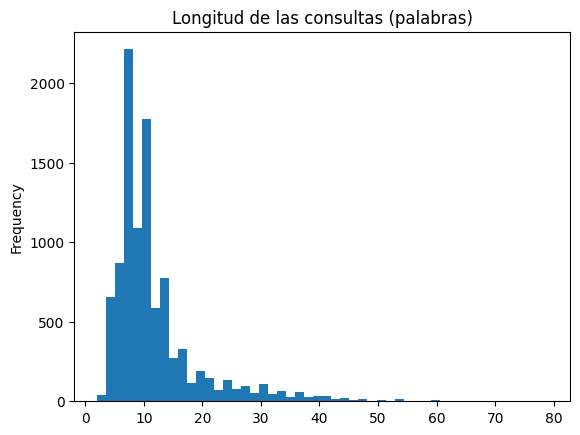

— card_arrival → I am still waiting on my card?
— card_arrival → What can I do if my card still hasn't arrived after 2 weeks?
— card_arrival → I have been waiting over a week. Is the card still coming?


In [ ]:
import pandas as pd, matplotlib.pyplot as plt
df = ds["train"].to_pandas()
print(df.shape, df.isna().sum().to_dict(), df.duplicated(subset="text").sum())
print(df["label"].value_counts())                 # 77 clases: revisa el mínimo por clase
df["n_palabras"] = df["text"].str.split().str.len()
print(df["n_palabras"].describe())
df["n_palabras"].plot(kind="hist", bins=50, title="Longitud de las consultas (palabras)")
plt.show()

# Obtenemos los nombres reales de las etiquetas a partir de las características del dataset
nombres = ds["train"].features["label"].names

for i in range(3):
    # Usamos el id de la etiqueta (df["label"][i]) para buscar su nombre correspondiente
    print("—", nombres[df["label"][i]], "→", df["text"][i][:200])

Fine-tuning de un modelo BERT

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

checkpoint = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=77)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### Tokenización del Dataset
Ahora aplicamos el `tokenizer` sobre nuestro dataset (`ds`). Usamos la función `.map()` para procesar todos los textos en lotes rápidos.

In [ ]:
def tokenizar_funcion(ejemplos):
    # Aplicamos el tokenizador a la columna 'text'
    # truncamos si el texto supera el max_length establecido (64 es suficiente)
    return tokenizer(ejemplos["text"], truncation=True, max_length=64)

# Aplicamos la función de tokenización a todas las particiones (splits) del dataset
ds_tokenizado = ds.map(tokenizar_funcion, batched=True)

# Observa cómo ahora el dataset tiene nuevas columnas necesarias para el modelo:
# 'input_ids' y 'attention_mask'
print(ds_tokenizado)
print("Ejemplo tokenizado:", ds_tokenizado["train"][0])

Map:   0%|          | 0/10003 [00:00<?, ? examples/s]

Map:   0%|          | 0/3080 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 10003
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3080
    })
})
Ejemplo tokenizado: {'text': 'I am still waiting on my card?', 'label': 11, 'input_ids': [101, 1045, 2572, 2145, 3403, 2006, 2026, 4003, 1029, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


### Configuración del Data Collator
Utilizaremos `DataCollatorWithPadding` para realizar un padding dinámico por lote en lugar de rellenar de forma estática todas las frases a 64 tokens.

In [ ]:
from transformers import DataCollatorWithPadding

# Configuramos el colador de datos asociándolo a nuestro tokenizador
collator = DataCollatorWithPadding(tokenizer=tokenizer)

# El colador está listo para pasarse como argumento `data_collator=collator` en el Trainer

### Definición de métricas de evaluación
Configuramos la función `compute_metrics` para calcular el Accuracy y el F1-Score (macro) durante la evaluación del modelo.

In [ ]:
import numpy as np
import evaluate

# Cargamos las métricas estándar desde la librería evaluate
metric_accuracy = evaluate.load("accuracy")
metric_f1 = evaluate.load("f1")

def compute_metrics(eval_pred):
    # Extraemos las predicciones (logits) y las etiquetas reales
    logits, labels = eval_pred

    # Obtenemos la clase con mayor probabilidad para cada predicción
    predictions = np.argmax(logits, axis=-1)

    # Calculamos el Accuracy
    acc = metric_accuracy.compute(predictions=predictions, references=labels)["accuracy"]

    # Calculamos el F1-Score usando promedio 'macro' debido a que son 77 clases
    f1 = metric_f1.compute(predictions=predictions, references=labels, average="macro")["f1"]

    return {
        "eval_accuracy": acc,
        "eval_f1": f1
    }

Ajuste hiperparametros

In [ ]:
import pandas as pd, time
from transformers import TrainingArguments, Trainer

# Creamos train_small y val_small a partir de ds_tokenizado si no están definidos
if 'train_small' not in globals() or 'val_small' not in globals():
    # Partimos el dataset en train y test (90% / 10%)
    split_ds = ds_tokenizado["train"].train_test_split(test_size=0.1, seed=42)
    # Seleccionamos subconjuntos pequeños para acelerar la búsqueda de hiperparámetros
    train_small = split_ds["train"].shuffle(seed=42).select(range(1000))
    val_small = split_ds["test"].shuffle(seed=42).select(range(200))

resultados = []
for lr in [2e-5, 3e-5, 5e-5]:
    for ep in [2, 3]:
        args = TrainingArguments(
            output_dir=f"{OUT}/tmp_lr{lr}_ep{ep}",
            learning_rate=lr, num_train_epochs=ep,
            per_device_train_batch_size=16, per_device_eval_batch_size=32,
            eval_strategy="epoch", save_strategy="no",
            fp16=True, report_to="none", seed=42,
        )
        t0 = time.time()
        tr = Trainer(model=AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=77),
                     args=args, train_dataset=train_small, eval_dataset=val_small,
                     data_collator=collator, compute_metrics=compute_metrics,
                     processing_class=tokenizer)
        tr.train()
        m = tr.evaluate()
        resultados.append({"lr": lr, "epochs": ep, **m, "min": round((time.time()-t0)/60, 1)})

pd.DataFrame(resultados).sort_values("eval_f1", ascending=False)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,4.248203,0.065000,0.022098
2,No log,4.183906,0.130000,0.080004


Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,4.183906,2,0.130000,0.080004


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (15 outputs left out)

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,3.987305,0.230000,0.137909
2,No log,3.553565,0.340000,0.213945
3,No log,3.398096,0.400000,0.269364


Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,3.398096,3,0.400000,0.269364


,lr,epochs,eval_accuracy,eval_f1,eval_loss,min
5,0.00005,3,0.400,0.269364,3.398096,0.1
3,0.00003,3,0.335,0.230486,3.774922,0.1
4,0.00005,2,0.255,0.162219,3.873867,0.1
1,0.00002,3,0.245,0.148484,4.018808,0.2
2,0.00003,2,0.160,0.105197,4.087646,0.1
0,0.00002,2,0.130,0.080004,4.183906,0.2


prueba adicional

In [ ]:
import pandas as pd, time
from transformers import TrainingArguments, Trainer

# Creamos train_small y val_small a partir de ds_tokenizado si no están definidos
if 'train_small' not in globals() or 'val_small' not in globals():
    # Partimos el dataset en train y test (90% / 10%)
    split_ds = ds_tokenizado["train"].train_test_split(test_size=0.1, seed=42)
    # Seleccionamos subconjuntos pequeños para acelerar la búsqueda de hiperparámetros
    train_small = split_ds["train"].shuffle(seed=42).select(range(1000))
    val_small = split_ds["test"].shuffle(seed=42).select(range(200))

resultados = []
for lr in [5e-5, 7e-5, 9e-5]:
    for ep in [4, 5, 6]:
        args = TrainingArguments(
            output_dir=f"{OUT}/tmp_lr{lr}_ep{ep}",
            learning_rate=lr, num_train_epochs=ep,
            per_device_train_batch_size=16, per_device_eval_batch_size=32,
            eval_strategy="epoch", save_strategy="no",
            fp16=True, report_to="none", seed=42,
        )
        t0 = time.time()
        tr = Trainer(model=AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=77),
                     args=args, train_dataset=train_small, eval_dataset=val_small,
                     data_collator=collator, compute_metrics=compute_metrics,
                     processing_class=tokenizer)
        tr.train()
        m = tr.evaluate()
        resultados.append({"lr": lr, "epochs": ep, **m, "min": round((time.time()-t0)/60, 1)})

pd.DataFrame(resultados).sort_values("eval_f1", ascending=False)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,4.012168,0.205000,0.129943
2,No log,3.463110,0.390000,0.269908
3,No log,3.121553,0.480000,0.330033
4,No log,2.997258,0.505000,0.352070


Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,2.997258,4,0.505000,0.352070


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (27 outputs left out)

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,3.697559,0.365000,0.222442
2,No log,2.758240,0.465000,0.313238
3,No log,2.137579,0.565000,0.430049
4,No log,1.735905,0.630000,0.528983
5,No log,1.545982,0.645000,0.549359
6,No log,1.469741,0.670000,0.574483


Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,1.469741,6,0.670000,0.574483


,lr,epochs,eval_accuracy,eval_f1,eval_loss,min
8,0.00009,6,0.670,0.574483,1.469741,0.3
7,0.00009,5,0.645,0.554155,1.821409,0.2
5,0.00007,6,0.635,0.531869,1.813730,0.3
4,0.00007,5,0.570,0.435621,2.174886,0.2
2,0.00005,6,0.570,0.432507,2.308413,0.3
6,0.00009,4,0.535,0.393132,2.272365,0.2
3,0.00007,4,0.525,0.383313,2.600041,0.2
1,0.00005,5,0.525,0.379272,2.646096,0.2
0,0.00005,4,0.505,0.352070,2.997258,0.2


Entrenamiento completo con el mejor modelo

In [ ]:
training_args = TrainingArguments(
    output_dir=f"{OUT}/mejor_modelo",
    learning_rate=9e-5,
    num_train_epochs=6,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_f1",
    greater_is_better=True,
    weight_decay=0.01,
    warmup_steps=100,
    fp16=True,
    report_to="none",
    seed=42,
)

In [ ]:
trainer = Trainer(
    model=AutoModelForSequenceClassification.from_pretrained(
        checkpoint,
        num_labels=77
    ),
    args=training_args,
    train_dataset=ds_tokenizado["train"],
    eval_dataset=ds_tokenizado["test"],
    data_collator=collator,
    compute_metrics=compute_metrics,
    processing_class=tokenizer,
)

trainer.train()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,2.000353,0.505132,0.868182,0.864379
2,0.410400,0.337536,0.905844,0.905369
3,0.215296,0.346493,0.916558,0.916381
4,0.079910,0.309927,0.927597,0.927612
5,0.028757,0.314422,0.930519,0.930579
6,0.019475,0.324752,0.934416,0.934333


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=3756, training_loss=0.38431597993777583, metrics={'train_runtime': 213.8079, 'train_samples_per_second': 280.71, 'train_steps_per_second': 17.567, 'total_flos': 609872300052660.0, 'train_loss': 0.38431597993777583, 'epoch': 6.0})